In [1]:
!pip install pandas 
!pip install numpy
!pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable


In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [3]:
train_data = pd.read_csv("train_data.csv")

train_data.head()

,x,y
0,6.1101,17.5920
1,5.5277,9.1302
2,8.5186,13.6620
3,7.0032,11.8540
4,5.8598,6.8233


In [4]:
X = train_data["x"].values
Y = train_data["y"].values

## Plotting raw datapoints

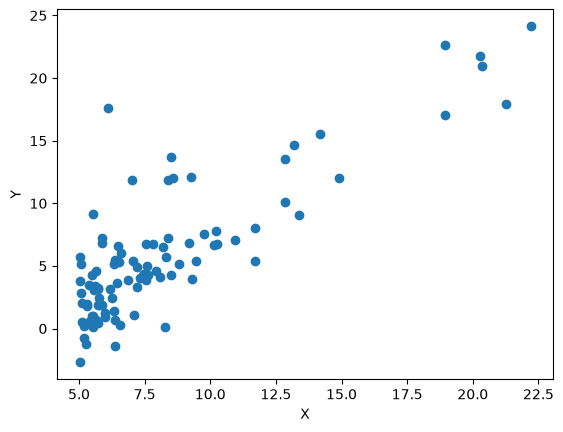

In [5]:
plt.scatter(X, Y)
plt.xlabel("X")
plt.ylabel("Y")
plt.show()

## Loss function

In [6]:
w = 0
b = 0

y_pred = w * X[0] + b
loss = (y_pred - Y[0]) ** 2

print("Loss:", loss)

Loss: 309.478464


## Cost Function

The loss function measures the error for one data point, while the cost function calculates the average squared error across all training examples, divided by 2.

$$
J(w,b)=\frac{1}{2m}\sum_{i=1}^{m}(\hat{y}_i-y_i)^2
$$

where,

- $m$ = number of training examples
- $\hat{y}_i=wx_i+b$ = predicted value
- $y_i$ = actual value
- $w$ = weight and $b$ = bias

The goal is to find the values of $w$ and $b$ that minimize the cost function.

In [7]:
def cost_function(X, Y, w, b):            # cost function => J(w,b) = 1/(2m) * sum((y)^ - y)**2)
    y_pred = w * X + b
    return np.sum((y_pred - Y) ** 2) / (2 * len(X))     

In [8]:
print("Cost at w=0, b=0:", cost_function(X, Y, 0, 0))

Cost at w=0, b=0: 32.072733877455676


In [9]:
print("Cost at w=2, b=1:", cost_function(X, Y, 2, 1))

Cost at w=2, b=1: 75.20338497891959


## Calculating Gradients

Gradients tell us how the cost changes when we change the weight or bias. They help us decide how to update these parameters to reduce the cost.

**Gradient with respect to weight:**

$$
\frac{\partial J}{\partial w}
=\frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)x_i
$$

**Gradient with respect to bias:**

$$
\frac{\partial J}{\partial b}
=\frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i-y_i)
$$

Here, $\hat{y}_i=wx_i+b$, $y_i$ is the actual value, and $m$ is the number of training examples.

The gradients are used to update $w$ and $b$ during Gradient Descent.

In [10]:
def gradient(X, Y, w, b):
    y_pred = w * X + b
    error = y_pred - Y

    dw = np.sum(error * X) / len(X)
    db = np.sum(error) / len(X)

    return dw, db

In [11]:
w = 0
b = 0

dw, db = gradient(X, Y, w, b)

print("dw =", dw)
print("db =", db)

dw = -65.32884974555671
db = -5.839135051546393


## Cost Function vs Weight

This graph shows how the cost changes for different values of weight while keeping the bias fixed at $b=0$.

The lowest point represents the weight that gives the minimum cost under this condition. Gradient Descent will help us update the weight and bias together to reduce the cost.

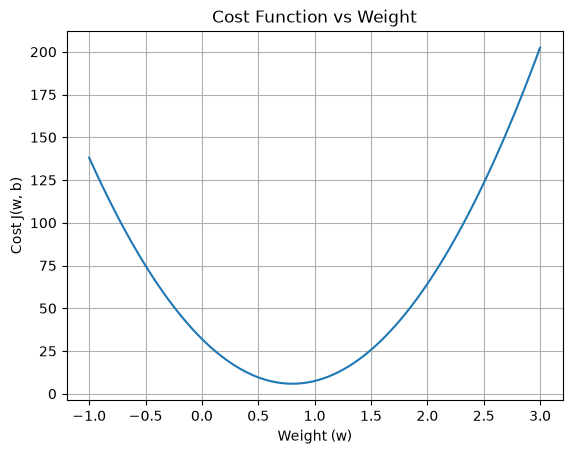

In [12]:
w_values = np.linspace(-1, 3, 100)
cost_values = [cost_function(X, Y, w, 0) for w in w_values]

plt.plot(w_values, cost_values)
plt.xlabel("Weight (w)")
plt.ylabel("Cost J(w, b)")
plt.title("Cost Function vs Weight")
plt.grid()
plt.show()

## Gradient Descent

Gradient Descent is an optimization algorithm used to find the weight and bias that minimize the cost function.

The parameters are updated using the following equations:

$$
w_{\text{new}}=w_{\text{old}}-\alpha\frac{\partial J}{\partial w}
$$

$$
b_{\text{new}}=b_{\text{old}}-\alpha\frac{\partial J}{\partial b}
$$

Here, $\alpha$ is the learning rate, which controls the size of each update.

In [13]:
w = 0
b = 0
alpha = 0.01
iterations = 1000

cost_history = []

for i in range(iterations):
    dw, db = gradient(X, Y, w, b)

    w = w - alpha * dw
    b = b - alpha * db

    cost_history.append(cost_function(X, Y, w, b))

print("Weight:", w)
print("Bias:", b)
print("Final cost:", cost_history[-1])

Weight: 1.1272942024281842
Bias: -3.241402144274422
Final cost: 4.515955503078914


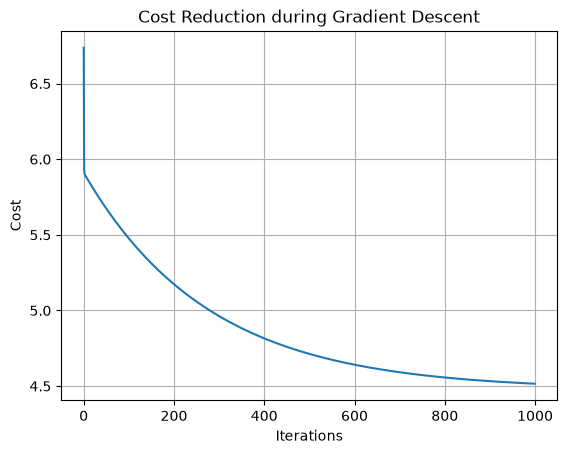

In [14]:
plt.plot(cost_history)
plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Reduction during Gradient Descent")
plt.grid()
plt.show()

## Learning Rate Selection

The learning rate controls how much the weight and bias change in each iteration. We try different learning rates and compare their final costs to find the best value among them.

In [15]:
learning_rates = [0.001, 0.003, 0.005, 0.01, 0.015, 0.02]
final_costs = []

for lr in learning_rates:
    w_test = 0
    b_test = 0

    for i in range(1000):
        dw, db = gradient(X, Y, w_test, b_test)
        w_test = w_test - lr * dw
        b_test = b_test - lr * db

    final_costs.append(cost_function(X, Y, w_test, b_test))

print("Learning rates:", learning_rates)
print("Final costs:", final_costs)

Learning rates: [0.001, 0.003, 0.005, 0.01, 0.015, 0.02]
Final costs: [np.float64(5.480269332020323), np.float64(4.964695258134313), np.float64(4.714002349533667), np.float64(4.515955503078914), np.float64(4.483372590612986), np.float64(4.478020743321126)]


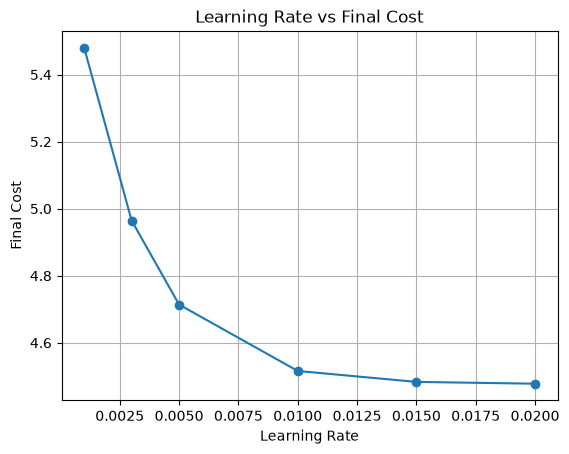

Best learning rate: 0.02
Lowest final cost: 4.478020743321126


In [16]:
plt.plot(learning_rates, final_costs, marker="o")
plt.xlabel("Learning Rate")
plt.ylabel("Final Cost")
plt.title("Learning Rate vs Final Cost")
plt.grid()
plt.show()

best_index = np.argmin(final_costs)
best_alpha = learning_rates[best_index]

print("Best learning rate:", best_alpha)
print("Lowest final cost:", final_costs[best_index])

## Training the Model with the Selected Learning Rate

After comparing the candidate learning rates, we select the one that produces the lowest finite final cost. We then train the model again from the initial values \(w=0\) and \(b=0\) using the selected learning rate.

The resulting weight and bias are used to generate the final regression line and predicted output values.

In [17]:
w = 0
b = 0
alpha = best_alpha

for i in range(1000):
    dw, db = gradient(X, Y, w, b)
    w = w - alpha * dw
    b = b - alpha * db

print("Weight:", w)
print("Bias:", b)
print("Final cost:", cost_function(X, Y, w, b))

Weight: 1.1822480052540145
Bias: -3.7884192615511796
Final cost: 4.478020743321126


## Actual and Predicted Values

The prediction table compares the actual output with the output predicted by our trained model.

In [18]:
y_pred = w * X + b

pd.DataFrame({
    "X": X,
    "Actual Y": Y,
    "Predicted Y": y_pred
}).round(3)

,X,Actual Y,Predicted Y
0,6.110,17.592,3.435
1,5.528,9.130,2.747
2,8.519,13.662,6.283
3,7.003,11.854,4.491
4,5.860,6.823,3.139
...,...,...,...
92,5.871,7.203,3.152
93,5.305,1.987,2.484
94,8.293,0.145,6.016
95,13.394,9.055,12.047


## Plotting the Regression Line

After applying Gradient Descent, we use the optimized weight and bias to calculate the predicted values.

$$
\hat{y}=wx+b
$$

The regression line shows the relationship learned by the model between the input $x$ and output $y$.

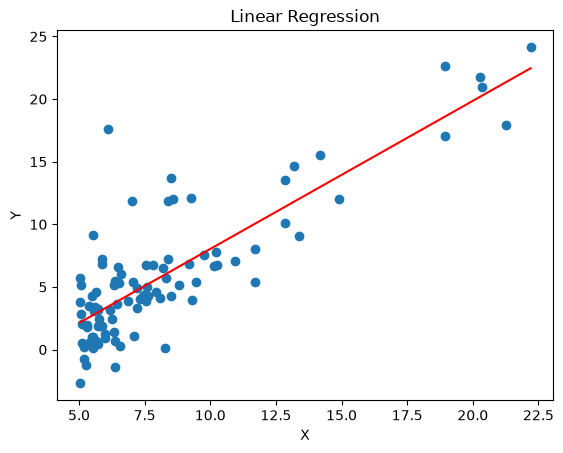

In [19]:
x_line = np.sort(X)

plt.scatter(X, Y)
plt.plot(x_line, w * x_line + b, color="red")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Linear Regression")
plt.show()

## Model Evaluation

After training the model, we evaluate its predictions using Mean Squared Error (MSE) and the coefficient of determination ($R^2$).

MSE measures the average squared difference between actual and predicted values.

$$
MSE=\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2
$$

The $R^2$ score indicates how much of the variation in the target values is explained by the model.

In [20]:
mse = np.mean((Y - y_pred) ** 2)
mae = np.mean(np.abs(Y - y_pred))
rmse = np.sqrt(mse)
r2 = 1 - np.sum((Y - y_pred) ** 2) / np.sum((Y - np.mean(Y)) ** 2)

print("MSE:", mse)
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MSE: 8.956041486642253
MAE: 2.2009382333439533
RMSE: 2.9926646131236043
R2 Score: 0.7019617122928004


## Conclusion

In this experiment, we implemented linear regression from scratch using Gradient Descent. We calculated the cost function and gradients, trained the model, and compared different learning rates. We then plotted the regression line, compared actual and predicted values, and evaluated the model using MSE, RMSE, MAE, and \(R^2\).